# JEDI Gradient Boosting Baseline

**Goal:** train a boosting-based classifier for `applied=yes/no`.

This notebook keeps the same production-realistic feature policy: no personal preference score columns are used as model inputs.

## What Gradient Boosting Is

Gradient boosting trains many small decision trees sequentially.

Each new tree tries to fix the mistakes made by the previous trees.

For JEDI, this can help capture interactions like:

```text
remote is okay if entry-level and India
remote is risky if senior/global
backend is good if experience_min is low
AI is good only if not staff/principal
```

Important implementation detail:

Our preprocessing creates many sparse TF-IDF and one-hot features. Classic `GradientBoostingClassifier` expects dense input, so this notebook compresses the sparse feature matrix with `TruncatedSVD` before training the boosting model.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score,
    brier_score_loss, classification_report, confusion_matrix, f1_score,
    log_loss, precision_score, recall_score, roc_auc_score
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.utils.class_weight import compute_sample_weight

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 140)

RANDOM_STATE = 42
DATA_PATH = Path("../../data/jedi_master_prepared.csv")


## 1. Load Dataset And Target

In [2]:
df = pd.read_csv(DATA_PATH)
df["applied_clean"] = df["applied"].astype(str).str.strip().str.lower()
df["target_applied"] = df["applied_clean"].map({"yes": 1, "no": 0})

if df["target_applied"].isna().any():
    raise ValueError(df.loc[df["target_applied"].isna(), "applied"].value_counts(dropna=False))

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]:,}")
display(df[["applied", "target_applied"]].value_counts().rename("count").reset_index())
display(df.head(3))

Rows: 331 | Columns: 53


,applied,target_applied,count
0,no,0,205
1,yes,1,126


,row_id,source_platform,source_type,scraped_at,can_apply_now,company_name,company_match_score,role_title,role_title_preference_score,role_family,role_family_preference_score,seniority,seniority_profile_fit_score,location,location_profile_fit_score,work_mode,work_mode_fit_score,employment_type,experience_min_years,experience_max_years,experience_profile_fit_score,skills_or_requirements,skills_profile_fit_score,salary_min,salary_max,salary_profile_fit_score,freshness,overall_preference_score,preference_reason,applied,apply_url,skills_or_requirements_original,skills_array,has_skills_or_requirements,skills_imputation_type,role_family_standard,seniority_standard,employment_type_standard,work_mode_standard,city_standard,country_standard,location_bucket,is_bengaluru,is_gurgaon_ncr,is_india,experience_min_bucket,salary_midpoint,salary_available,near_duplicate_key,company_name_standard,role_title_standard,applied_clean,target_applied
0,1,Greenhouse,deterministic_scrape_candidate,27-06-2026,Yes,Nirmata,4,"Software Engineer Intern, India",5,Backend / Cloud,4,intern,5,"Bangalore, Hybrid",4,Hybrid,5,internship,0.0,1.0,5.0,Go; Java; microservices; Kubernetes; Prometheus; TimeScale; reliability; automation,2,1200000,1200000,5,Not visible,3,"Intern role is fine, everything is good but the requirements state Kubernetes, observability tools, promethus and Go which dont match wi...",no,https://job-boards.greenhouse.io/nirmata/jobs/5040355008,Go; Java; microservices; Kubernetes; Prometheus; TimeScale; reliability; automation,"[""go"",""java"",""microservices"",""kubernetes"",""prometheus"",""timescale"",""reliability"",""automation""]",True,original,backend,intern,internship,hybrid,bengaluru,india,bengaluru,True,False,True,0,1200000,True,nirmata|software_engineer_intern_india|bengaluru,nirmata,software_engineer_intern_india,no,0
1,2,Greenhouse,deterministic_scrape_candidate,27-06-2026,Yes,CloudSEK,5,SDE - Backend - Intern,5,Backend,5,intern,5,"Bengaluru, Karnataka, India",4,Hybrid,5,internship,0.0,1.0,5.0,Backend engineering; cybersecurity product; APIs; databases likely,4,800000,900000,4,Not visible,4,"Backend intern in Bengaluru; very relevant for fresher profile, salary is a little less and location bengaluru",yes,https://job-boards.greenhouse.io/cloudsek/jobs/5766402004,Backend engineering; cybersecurity product; APIs; databases likely,"[""backend engineering"",""cybersecurity product"",""apis"",""databases likely""]",True,original,backend,intern,internship,hybrid,bengaluru,india,bengaluru,True,False,True,0,850000,True,cloudsek|sde_backend_intern|bengaluru,cloudsek,sde_backend_intern,yes,1
2,3,Greenhouse,deterministic_scrape_candidate,27-06-2026,Yes,Anaplan,5,Associate Software Engineer,5,Backend / Fullstack,5,entry_level,5,"Gurugram, India",5,unknown,5,full_time,0.0,2.0,5.0,Software engineering; AI-infused platform; SaaS; cloud; planning systems,5,500000,700000,2,Not visible,3,Associate level in Gurgaon; high-quality company and location fitbut salary is quite less and the bad factor,yes,https://job-boards.greenhouse.io/anaplan/jobs/8511489002,Software engineering; AI-infused platform; SaaS; cloud; planning systems,"[""software engineering"",""ai-infused platform"",""saas"",""cloud"",""planning systems""]",True,original,fullstack,entry_level,full_time,unknown,delhi_ncr,india,delhi_ncr,False,True,True,0,600000,True,anaplan|associate_software_engineer|delhi_ncr,anaplan,associate_software_engineer,yes,1


## 2. Feature Policy

Exclude score labels, identifiers, metadata, and explanation leakage. Use job facts only.

In [3]:
score_columns = [c for c in df.columns if c.endswith("_score")]
drop_columns = sorted(set([
    "row_id", "apply_url", "source_platform", "source_type", "scraped_at",
    "applied", "applied_clean", "target_applied", "overall_preference_score",
    "preference_reason", "near_duplicate_key", "company_name_standard", "role_title_standard",
] + score_columns))

text_source_columns = ["company_name", "role_title", "role_family", "seniority", "location", "skills_or_requirements", "skills_array"]
categorical_features = ["can_apply_now", "role_family_standard", "seniority_standard", "employment_type_standard", "work_mode_standard", "city_standard", "country_standard", "location_bucket", "experience_min_bucket", "skills_imputation_type", "freshness"]
numeric_features = ["experience_min_years", "salary_min", "salary_max", "salary_midpoint"]
boolean_features = ["has_skills_or_requirements", "is_bengaluru", "is_gurgaon_ncr", "is_india", "salary_available"]

display(pd.DataFrame({"feature": text_source_columns + categorical_features + numeric_features + boolean_features}))
display(pd.DataFrame({"dropped_column": [c for c in drop_columns if c in df.columns]}))

,feature
0,company_name
1,role_title
2,role_family
3,seniority
4,location
5,skills_or_requirements
6,skills_array
7,can_apply_now
8,role_family_standard
9,seniority_standard


,dropped_column
0,applied
1,applied_clean
2,apply_url
3,company_match_score
4,company_name_standard
5,experience_profile_fit_score
6,location_profile_fit_score
7,near_duplicate_key
8,overall_preference_score
9,preference_reason


## 3. Build Modeling Table

In [4]:
model_df = df.copy()
for col in text_source_columns:
    model_df[col] = model_df[col].fillna("").astype(str)

model_df["job_text"] = (
    model_df["company_name"] + " " + model_df["role_title"] + " " + model_df["role_family"] + " "
    + model_df["seniority"] + " " + model_df["location"] + " "
    + model_df["skills_or_requirements"] + " " + model_df["skills_array"]
)

def bool_to_int(value):
    text = str(value).strip().lower()
    if text in {"true", "1", "yes", "y"}: return 1
    if text in {"false", "0", "no", "n"}: return 0
    return np.nan

for col in boolean_features:
    model_df[col] = model_df[col].map(bool_to_int)
for col in numeric_features:
    model_df[col] = pd.to_numeric(model_df[col], errors="coerce")

feature_columns = ["job_text"] + categorical_features + numeric_features + boolean_features
X = model_df[feature_columns].copy()
y = model_df["target_applied"].astype(int)
display(X.head(3))

,job_text,can_apply_now,role_family_standard,seniority_standard,employment_type_standard,work_mode_standard,city_standard,country_standard,location_bucket,experience_min_bucket,skills_imputation_type,freshness,experience_min_years,salary_min,salary_max,salary_midpoint,has_skills_or_requirements,is_bengaluru,is_gurgaon_ncr,is_india,salary_available
0,"Nirmata Software Engineer Intern, India Backend / Cloud intern Bangalore, Hybrid Go; Java; microservices; Kubernetes; Prometheus; TimeSc...",Yes,backend,intern,internship,hybrid,bengaluru,india,bengaluru,0,original,Not visible,0.0,1200000,1200000,1200000,1,1,0,1,1
1,"CloudSEK SDE - Backend - Intern Backend intern Bengaluru, Karnataka, India Backend engineering; cybersecurity product; APIs; databases l...",Yes,backend,intern,internship,hybrid,bengaluru,india,bengaluru,0,original,Not visible,0.0,800000,900000,850000,1,1,0,1,1
2,"Anaplan Associate Software Engineer Backend / Fullstack entry_level Gurugram, India Software engineering; AI-infused platform; SaaS; clo...",Yes,fullstack,entry_level,full_time,unknown,delhi_ncr,india,delhi_ncr,0,original,Not visible,0.0,500000,700000,600000,1,0,1,1,1


## 4. Train/Test Split

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

def class_distribution(labels, name):
    out = labels.value_counts().rename_axis("class").reset_index(name="count")
    out["share"] = out["count"] / len(labels)
    out["set"] = name
    return out[["set", "class", "count", "share"]]

display(pd.concat([class_distribution(y_train, "train"), class_distribution(y_test, "test")], ignore_index=True))

,set,class,count,share
0,train,0,164,0.621212
1,train,1,100,0.378788
2,test,0,41,0.611940
3,test,1,26,0.388060


## 5. Preprocessing + SVD Compression

`TruncatedSVD` compresses the sparse text/category matrix into dense components.

This lets classic gradient boosting train on the compressed representation.

In [6]:
numeric_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
categorical_pipeline = Pipeline(steps=[("imputer", SimpleImputer(strategy="constant", fill_value="missing")), ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=3))])
text_vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=1200)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features + boolean_features),
        ("categorical", categorical_pipeline, categorical_features),
        ("text", text_vectorizer, "job_text"),
    ],
    remainder="drop",
    verbose_feature_names_out=True,
)

svd = TruncatedSVD(n_components=80, random_state=RANDOM_STATE)
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featu

## 6. Train Gradient Boosting

Important parameters:

- `n_estimators`: number of boosting stages
- `learning_rate`: how strongly each tree contributes
- `max_depth`: depth of each tree
- `subsample`: less than 1.0 adds stochasticity and can reduce overfitting

`GradientBoostingClassifier` does not have `class_weight`, so we pass `sample_weight` during `.fit()`.

In [7]:
gb = GradientBoostingClassifier(
    n_estimators=150,
    learning_rate=0.05,
    max_depth=2,
    subsample=0.85,
    random_state=RANDOM_STATE,
)

model = Pipeline(steps=[("preprocess", preprocessor), ("svd", svd), ("classifier", gb)])
sample_weight = compute_sample_weight(class_weight="balanced", y=y_train)
model.fit(X_train, y_train, classifier__sample_weight=sample_weight)
print("Gradient boosting trained.")
model

Gradient boosting trained.


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('svd', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the differe

## 7. Evaluate

In [8]:
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
    "precision_yes": precision_score(y_test, y_pred, zero_division=0),
    "recall_yes": recall_score(y_test, y_pred, zero_division=0),
    "f1_yes": f1_score(y_test, y_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, y_proba),
    "average_precision": average_precision_score(y_test, y_proba),
    "log_loss": log_loss(y_test, y_proba),
    "brier_score": brier_score_loss(y_test, y_proba),
}
display(pd.DataFrame([metrics]).T.rename(columns={0: "score"}))
print(classification_report(y_test, y_pred, target_names=["no", "yes"], zero_division=0))
display(pd.DataFrame(confusion_matrix(y_test, y_pred), index=["actual_no", "actual_yes"], columns=["pred_no", "pred_yes"]))

,score
accuracy,0.925373
balanced_accuracy,0.917917
precision_yes,0.920000
recall_yes,0.884615
f1_yes,0.901961
roc_auc,0.918386
average_precision,0.898197
log_loss,0.299486
brier_score,0.077915


              precision    recall  f1-score   support

          no       0.93      0.95      0.94        41
         yes       0.92      0.88      0.90        26

    accuracy                           0.93        67
   macro avg       0.92      0.92      0.92        67
weighted avg       0.93      0.93      0.93        67



,pred_no,pred_yes
actual_no,39,2
actual_yes,3,23


## 8. Threshold Table

,threshold,predicted_yes_count,precision_yes,recall_yes,f1_yes,balanced_accuracy
0,0.20,31,0.774194,0.923077,0.842105,0.876173
1,0.25,28,0.857143,0.923077,0.888889,0.912758
2,0.30,27,0.851852,0.884615,0.867925,0.893527
3,0.35,27,0.851852,0.884615,0.867925,0.893527
4,0.40,26,0.884615,0.884615,0.884615,0.905722
5,0.45,25,0.920000,0.884615,0.901961,0.917917
6,0.50,25,0.920000,0.884615,0.901961,0.917917
7,0.55,22,0.954545,0.807692,0.875000,0.891651
8,0.60,22,0.954545,0.807692,0.875000,0.891651
9,0.65,22,0.954545,0.807692,0.875000,0.891651


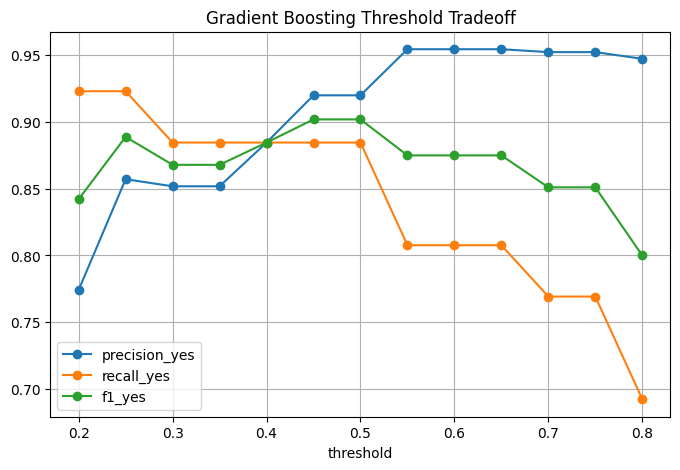

In [9]:
threshold_rows = []
for threshold in np.arange(0.20, 0.81, 0.05):
    pred = (y_proba >= threshold).astype(int)
    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "predicted_yes_count": int(pred.sum()),
        "precision_yes": precision_score(y_test, pred, zero_division=0),
        "recall_yes": recall_score(y_test, pred, zero_division=0),
        "f1_yes": f1_score(y_test, pred, zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_test, pred),
    })
threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df)
threshold_df.plot(x="threshold", y=["precision_yes", "recall_yes", "f1_yes"], marker="o", figsize=(8, 5), grid=True)
plt.title("Gradient Boosting Threshold Tradeoff")
plt.show()

## 9. Cross-Validation

This CV run does not pass sample weights. Treat it as directional model comparison, not final tuning.

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc", "average_precision": "average_precision"}
cv_results = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1, return_train_score=False)
cv_summary = []
for key, values in cv_results.items():
    if key.startswith("test_"):
        cv_summary.append({"metric": key.replace("test_", ""), "mean": np.mean(values), "std": np.std(values), "fold_scores": np.round(values, 3)})
display(pd.DataFrame(cv_summary).sort_values("metric"))

,metric,mean,std,fold_scores
0,accuracy,0.885391,0.035630,"[0.821, 0.894, 0.924, 0.909, 0.879]"
6,average_precision,0.890714,0.065176,"[0.805, 0.834, 0.955, 0.972, 0.888]"
1,balanced_accuracy,0.864841,0.037571,"[0.797, 0.883, 0.908, 0.88, 0.856]"
4,f1,0.838097,0.048996,"[0.75, 0.857, 0.894, 0.864, 0.826]"
2,precision,0.910498,0.062875,"[0.818, 0.875, 0.955, 1.0, 0.905]"
3,recall,0.778462,0.055997,"[0.692, 0.84, 0.84, 0.76, 0.76]"
5,roc_auc,0.923490,0.043532,"[0.856, 0.893, 0.954, 0.978, 0.937]"


## 10. Parameter Options

Try these later:

```python
n_estimators=[100, 150, 250]
learning_rate=[0.03, 0.05, 0.1]
max_depth=[1, 2, 3]
subsample=[0.7, 0.85, 1.0]
svd__n_components=[40, 80, 120]
```

If this beats logistic/SVM, it means non-linear interactions are important for your preference.

In [11]:
review_cols = ["company_name", "role_title", "role_family_standard", "seniority_standard", "location_bucket", "work_mode_standard", "employment_type_standard", "skills_or_requirements"]
test_review = df.loc[X_test.index, review_cols + ["applied"]].copy()
test_review["actual_applied_binary"] = y_test.values
test_review["predicted_applied_binary"] = y_pred
test_review["applied_probability"] = y_proba
test_review["error_type"] = np.select(
    [(test_review["actual_applied_binary"] == 1) & (test_review["predicted_applied_binary"] == 0), (test_review["actual_applied_binary"] == 0) & (test_review["predicted_applied_binary"] == 1)],
    ["false_negative", "false_positive"],
    default="correct",
)
OUTPUT_PATH = Path("../../data/jedi_gradient_boosting_test_predictions.csv")
test_review.sort_values("applied_probability", ascending=False).to_csv(OUTPUT_PATH, index=False)
print(f"Saved: {OUTPUT_PATH}")
display(test_review.sort_values("applied_probability", ascending=False).head(15))

Saved: data\jedi_gradient_boosting_test_predictions.csv


,company_name,role_title,role_family_standard,seniority_standard,location_bucket,work_mode_standard,employment_type_standard,skills_or_requirements,applied,actual_applied_binary,predicted_applied_binary,applied_probability,error_type
4,Energy Exemplar,Associate Software Engineer - Python,backend,entry_level,bengaluru,unknown,full_time,Python; algorithms; product development; possible data/optimization systems,yes,1,1,0.978908,correct
254,Weekday,Backend Engineer,backend,entry_level,bengaluru,onsite,full_time,Backend APIs; databases; Python/Node/Java likely; product engineering; startup pace,yes,1,1,0.976545,correct
255,Weekday,Data Engineer (Hybrid),data_engineering,entry_level,bengaluru,hybrid,full_time,Data pipelines; SQL; Python; ETL; analytics; cloud data workflows,yes,1,1,0.973309,correct
258,Weekday,GTM Engineer,fullstack,entry_level,bengaluru,onsite,full_time,Automation; scripting; integrations; AI tools; product workflows; light fullstack,yes,1,1,0.968272,correct
286,TopGrep Tech,Software Engineer Intern to hire,fullstack,intern,bengaluru,onsite,internship,JavaScript; ReactJS; MySQL/Mongo/PostgreSQL; Azure; AI; Docker; Jenkins; Kubernetes; DataScience; ML/Ops,yes,1,1,0.968087,correct
315,Origin,CVAT Annotation Intern,ml_ai,intern,bengaluru,onsite,internship,CVAT; data annotation; machine learning data; AI delivery; computer vision datasets,no,0,1,0.967187,false_positive
308,Lokal App,Backend SDE-1,backend,entry_level,bengaluru,onsite,full_time,Backend development; Python; Java; JavaScript; SQL/NoSQL databases; API design; product engineering,yes,1,1,0.960321,correct
317,Funding Societies | Modalku Group,Product Security Intern,other,intern,india_remote,remote,internship,Product security; Generative AI for security workflows; autonomous pentesting frameworks; secure SDLC; engineering culture,yes,1,1,0.956448,correct
253,Drivetrain,SDE (Automation & Quality Focus),backend,entry_level,india_remote,remote,full_time,Automation; QA; SDET; Python/JS likely; CI; testing frameworks,yes,1,1,0.955689,correct
280,Zynga,Software Engineering Intern,backend,intern,bengaluru,hybrid,internship,Data structures; algorithms; Java; C#; C/C++; JavaScript; Unix; game systems,yes,1,1,0.955031,correct


## 11. Student Deep Dive: How To Read This Gradient Boosting Notebook

Gradient boosting is a stronger, more flexible model than logistic regression. It builds many small trees one after another. Each new tree tries to fix mistakes made by the previous trees. This can produce excellent performance, but it also needs more caution on small datasets because it can learn patterns that do not generalize.

### What gradient boosting is doing

A single small tree learns a rough rule. Gradient boosting adds many small trees together. The first trees learn broad patterns like early-career versus senior roles. Later trees correct smaller mistakes, such as special cases for certain role families, locations, or wording patterns.

This model can learn interactions better than logistic regression. For example, it can learn that `remote` may be fine for one role type but less preferred for another, or that salary only matters after seniority and experience are considered.

### Why each preprocessing step exists

- `target_applied` is the numeric target: yes becomes 1 and no becomes 0.
- Preference score columns are dropped to avoid leakage. This classifier should predict the binary applied label from job attributes only.
- Source fields are dropped because the model should not learn source origin as a shortcut.
- Text columns are combined into `job_text`, giving the model access to title, role family, seniority, location, and skills wording.
- Numeric columns are imputed so missing values do not break the model.
- Numeric columns are scaled before SVD. Scaling keeps numeric columns from being badly mismatched with transformed text/category features.
- Categorical columns are one-hot encoded because trees still need numeric inputs after preprocessing.
- TF-IDF turns text into a sparse word/phrase matrix.
- `TruncatedSVD(n_components=80)` compresses the sparse TF-IDF and one-hot feature space into 80 dense components. This is needed because classic `GradientBoostingClassifier` does not work naturally with large sparse matrices. SVD keeps major patterns while reducing dimensionality.
- `compute_sample_weight(class_weight='balanced', y=y_train)` gives higher weight to the minority yes class during training. This helps the model care about yes examples despite the 62/38 class split.
- `GradientBoostingClassifier(n_estimators=150, learning_rate=0.05, max_depth=2, subsample=0.85)` creates many shallow trees. Shallow trees reduce overfitting; small learning rate makes each tree contribute gently; subsampling adds randomness to improve generalization.

### How to read the metrics

- Confusion matrix: this run produced `39 true no`, `2 false yes`, `3 false no`, and `23 true yes`.
- Accuracy: `0.925`, the best single held-out accuracy among the completed notebooks.
- Balanced accuracy: `0.918`, also the best held-out balanced score here.
- Precision for yes: `0.920`. When it recommends apply, it is very often correct.
- Recall for yes: `0.885`. It catches most jobs you labeled yes.
- F1 for yes: `0.902`, the best held-out F1 among these runs.
- ROC-AUC: `0.918`, strong but not higher than logistic regression. This means the classification threshold result is excellent, but ranking quality is not clearly superior.
- Average precision: `0.898`, solid but slightly below logistic on this run.
- Log loss and Brier score are probability quality metrics. Here Brier score `0.078` is strong, but still validate with more data before trusting exact probabilities.

### Interpreting this run

Gradient boosting gives the best held-out classification result: only 5 mistakes out of 67 test rows. It has the same number of false negatives as logistic regression but one fewer false positive. That makes it attractive.

The threshold table says threshold `0.45` or `0.50` gives F1 `0.902`. If you lower the threshold to `0.25`, recall increases to `0.923`, but precision drops to `0.857`. So the default threshold is already good for this split. For a daily screener where missing good roles is costly, a threshold around `0.40` to `0.50` is sensible.

The caution comes from cross-validation. CV mean F1 is about `0.838`, balanced accuracy about `0.865`, and recall about `0.778`. Those are good, but not dramatically better than logistic regression. The held-out split is likely a bit favorable. In a project writeup, say gradient boosting achieved the best single split result, while logistic regression remained the most interpretable and similarly strong under cross-validation.

Because SVD compresses the features, this model is less explainable. The model no longer sees direct columns like `text__backend` in a simple way; it sees compressed components. That is fine for performance, but weaker for explaining why a specific job was recommended.

### What action this suggests

Treat gradient boosting as the best performance candidate, not automatically the final model. It should be compared against logistic regression with grouped cross-validation, more labels, and calibration checks. If it keeps winning after more data, use it for ranking. If interpretability matters more for the resume project story, logistic regression is easier to defend.